Import Packages

In [1]:
import pandas as pd

Load the Data

In [2]:
df = pd.read_csv("WAHIS_data.csv")
print(df.head())

   Year      Semester World region  Country Administrative Division  \
0  2005  Jul-Dec 2005       Africa  Algeria                   Alger   
1  2005  Jul-Dec 2005       Africa  Algeria                   Alger   
2  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   
3  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   
4  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   

                                             Disease  \
0  Varroa spp. (Inf. of honey bees with) (Varroosis)   
1  Varroa spp. (Inf. of honey bees with) (Varroosis)   
2                        Bovine tuberculosis (-2018)   
3                        Bovine tuberculosis (-2018)   
4                       Brucella abortus (Inf. with)   

  Serotype/Subtype/Genotype         Animal Category Event_id Species  \
0                       NaN  Both animal categories        -     NaN   
1                       NaN                Domestic        -    Bees   
2                   

/var/folders/8y/fzsxk9yx41b8tt2slg_xz48m0000gn/T/ipykernel_56009/624074253.py:1: DtypeWarning: Columns (0: Event_id, 1: New outbreaks) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("WAHIS_data.csv")


Clean and Filter Data

In [3]:
# Filter for 2005 - 2024
df_filtered = df[df["Year"].between(2005, 2024)].copy()

# Identify orphan rows - species-detail rows without a summary row
group_cols = ["Year", "Semester", "World region", "Country", "Administrative Division", "Disease"]

is_smr = df_filtered["Outbreak_id"] == "-"

has_summary = (
    df_filtered.groupby(group_cols, dropna=False)["Animal Category"]
      .transform(lambda s: (s == "Both animal categories").any())
)
has_summary = has_summary.fillna(False).astype(bool)

orphan_mask = is_smr & ~has_summary
orphan_groups = df_filtered.loc[orphan_mask, group_cols].drop_duplicates()

print(f"{len(orphan_groups):,} orphan groups need a synthetic summary row")

# Build new rows shaped exactly like a real "Both animal categories" summary row
new_rows = orphan_groups.copy()
new_rows["Serotype/Subtype/Genotype"] = ""
new_rows["Animal Category"] = "Both animal categories"
new_rows["Species"] = ""
new_rows["Event_id"] = "-"
new_rows["Outbreak_id"] = "-"
new_rows["New outbreaks"] = 0 # Infer that those without summary row have 0 new outbreaks
new_rows["Susceptible"] = "-"
new_rows["Measuring units"] = "-"
new_rows["Cases"] = "-"
new_rows["Killed and disposed of"] = "-"
new_rows["Slaughtered"] = "-"
new_rows["Deaths"] = "-"
new_rows["Vaccinated"] = "-"

# Flag out synthetic rows so it's clear later which summary rows were real vs. inferred
df_filtered["is_synthetic_summary"] = False
new_rows["is_synthetic_summary"] = True

df_filtered = pd.concat([df_filtered, new_rows], ignore_index=True) # Use df_filtered if want to see species level data

print(f"Added {len(new_rows):,} synthetic summary rows. New total: {len(df_filtered):,}")

df_summary = df_filtered[df_filtered["Animal Category"] == "Both animal categories"] # Use df_summary to only see summary rows

82,775 orphan groups need a synthetic summary row
Added 82,775 synthetic summary rows. New total: 710,495


# Exploratory Data Analysis — Key Findings

| # | Trend | One-line summary |
|---|---|---|
| 1 | **African swine fever spreads worldwide** | ~20 → ~50 countries (2005–2023): Georgia 2007 → EU 2014 → China 2018 → SE Asia 2019 → Caribbean 2021 |
| 2 | **Lumpy skin disease leaves Africa** | Middle East 2012–14 → Balkans 2015–16 (stopped by vaccination) → South & East Asia 2019–24 |
| 3 | **Bird flu changes strain and moves into wild birds** | H5N1 → H5N8/H5N6 (2014–20) → new H5N1 (2021+); wild-bird countries 10 → 66 |
| 4 | **Clear seasonality** | Insect-borne diseases peak Jul–Dec (bluetongue 93%); bird flu peaks Jan–Jun (winter) |
| 5 | **Surges are specific epidemics** | France bluetongue 2008, Indonesia FMD + India LSD 2022, Germany bluetongue 2024, screwworm 2023–24 |
| 6 | **Endemic diseases are flat, then step down in 2020** | Rabies, brucellosis, bovine TB flat to 2019; the 2020 drop matches fewer countries reporting |

**Data checks (read before trusting totals)**
- **A. Reporting dropped in 2020** (COVID + new WAHIS platform), so a dip can be fewer reports, not less disease.
- **B. A few reports dominate totals.** The top 1% of country-disease-years = ~58% of all outbreaks (e.g. Iran bee disease 2011 = 918k). For trends, use **number of countries reporting** rather than raw outbreak totals.

**Data structure notes**
- Six-monthly reports have `Outbreak_id == "-"`. Rows with an `Outbreak_id` are immediate notifications.
- Outbreak counts live on summary rows (`Species` blank): the `"Both animal categories"` row, or the `Domestic`/`Wild` summary row if there's no "Both" row. Cases/deaths live on species rows.
- The synthetic-row step above sets ~52k groups to 0 outbreaks even though they have real counts on their Domestic/Wild summary rows (~849k outbreaks). The cells below build outbreak counts from the summary rows instead.
- Renamed diseases (e.g. Bovine TB in 2018/19, HPAI categories) are merged below.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Palette (fixed categorical order) and recessive axes
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY, INK, MUTED = "#b8b7b0", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 12, "axes.titlelocation": "left",
})

def milestones(ax, series, notes, color):
    """Mark and label key events on a yearly line. notes = {year: (label, y_offset_points)}"""
    for yr, (label, dy) in notes.items():
        y = series.get(yr, np.nan)
        ax.scatter([yr], [y], s=40, color=color, zorder=4, edgecolor="white", linewidth=1.5)
        ax.annotate(label, (yr, y), xytext=(0, dy), textcoords="offset points", ha="center",
                    fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))

def fmt_years(fig):
    """Whole-year ticks on every axis of a year-based figure"""
    for ax in fig.axes:
        ax.xaxis.set_major_locator(plt.MultipleLocator(5))
        ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%d"))

short = lambda d: d.split(" (")[0].replace(" virus", "")  # "Rabies virus (Inf. with)" -> "Rabies"

def shade_2020(ax):
    ax.axvspan(2019.5, 2021.5, color="#f1f0ec", zorder=0)
    ax.text(2020.5, 0.98, "reporting\ndisruption", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=7.5, color=MUTED)

eda = df[df["Year"].between(2005, 2024)].copy()

num_cols = ["New outbreaks", "Susceptible", "Cases", "Killed and disposed of", "Slaughtered", "Deaths", "Vaccinated"]
for c in num_cols:
    eda[c] = pd.to_numeric(eda[c], errors="coerce")  # "-" -> NaN

# Harmonise diseases that were renamed during the period
eda["Disease"] = eda["Disease"].replace({
    "Bovine tuberculosis (-2018)": "Bovine tuberculosis",
    "Mycobacterium tuberculosis complex (Inf. with)(2019-)": "Bovine tuberculosis",
    "High pathogenicity avian influenza viruses (Inf. with) (poultry)": "HPAI (poultry)",
    "Influenza A viruses of high pathogenicity (Inf. with) (non-poultry including wild birds) (2017-)": "HPAI (non-poultry/wild)",
})
BEE_DISEASES = eda.loc[eda["Disease"].str.contains("honey bees|Aethina", regex=True), "Disease"].unique()

smr = eda[eda["Outbreak_id"] == "-"]          # six-monthly reports
species_rows = smr[smr["Species"].notna()]   # cases / deaths / etc.

In [5]:
# Outbreak table: one row per group. Use the "Both" summary row if present, else sum the Domestic/Wild summary rows
summ = smr[smr["Species"].isna()]
both = summ[summ["Animal Category"] == "Both animal categories"][group_cols + ["New outbreaks"]]
by_cat = (summ[summ["Animal Category"] != "Both animal categories"]
          .groupby(group_cols, dropna=False)["New outbreaks"].sum().reset_index())
by_cat = by_cat.merge(both[group_cols].drop_duplicates(), on=group_cols, how="left", indicator=True)
by_cat = by_cat[by_cat["_merge"] == "left_only"].drop(columns="_merge")

outbreaks = pd.concat([both, by_cat], ignore_index=True)
outbreaks["Half"] = np.where(outbreaks["Semester"].str.startswith("Jan"), "Jan-Jun", "Jul-Dec")
print(f"{len(outbreaks):,} groups, {outbreaks['New outbreaks'].sum():,.0f} outbreaks")

# Presence: (Year, Country, Disease) where the disease was reported with >0 outbreaks or >0 cases.
# More robust than outbreak counts across the 2020 reporting change.
presence = pd.concat([
    outbreaks.loc[outbreaks["New outbreaks"] > 0, ["Year", "Country", "Disease"]],
    species_rows.loc[species_rows["Cases"] > 0, ["Year", "Country", "Disease"]],
]).drop_duplicates()
countries_with = presence.pivot_table(index="Year", columns="Disease", values="Country", aggfunc="nunique").fillna(0)

# First year each country reports a disease (2005-06 used as baseline)
first_seen = presence.groupby(["Disease", "Country"])["Year"].min().reset_index()
new_intros = first_seen[first_seen["Year"] >= 2007]

256,712 groups, 5,880,150 outbreaks


## Data check A: reporting dropped in 2020
Countries submitting reports fell from ~173 to 148 in 2020 because of COVID and the move to the new WAHIS platform (launched March 2021). From 2020 there are also many species rows with no outbreak count. **So a dip in 2020–21 can mean fewer reports, not less disease.**

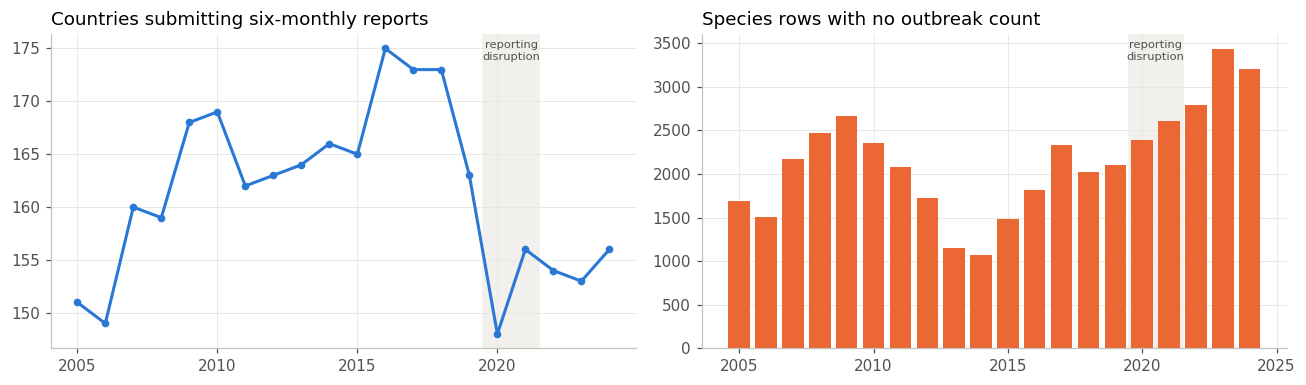

In [6]:
countries_per_year = smr.groupby("Year")["Country"].nunique()
no_count = species_rows[species_rows["New outbreaks"].isna()]
no_count = no_count.merge(summ[group_cols].drop_duplicates(), on=group_cols, how="left", indicator=True)
no_count_per_year = no_count[no_count["_merge"] == "left_only"].groupby("Year").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax in axes: shade_2020(ax)
axes[0].plot(countries_per_year.index, countries_per_year.values, marker="o", ms=4)
axes[0].set_title("Countries submitting six-monthly reports")
axes[1].bar(no_count_per_year.index, no_count_per_year.values, color=PALETTE[1], width=0.8)
axes[1].set_title("Species rows with no outbreak count")
fmt_years(fig); plt.tight_layout(); plt.show()

## Data check B: a few reports dominate the totals
The 10 largest country-disease-years below. Most are bee diseases (counted in hives) or one-off national reports, not real epidemics. **This is why the trends below use "number of countries reporting" rather than raw outbreak totals.**

Top 1% of country-disease-years = 58% of all outbreaks


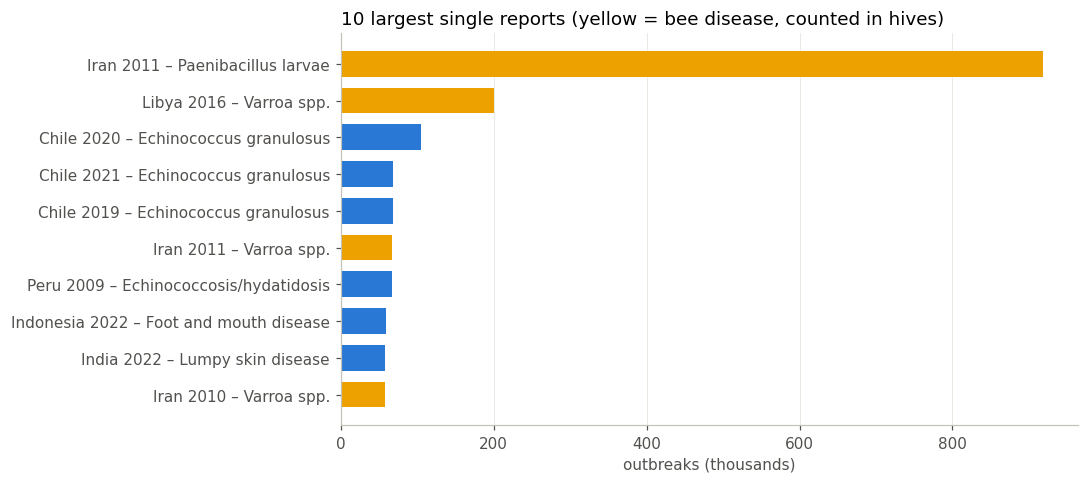

In [7]:
cdy = outbreaks.groupby(["Year", "Country", "Disease"])["New outbreaks"].sum().reset_index()
top1pct_share = cdy.nlargest(int(len(cdy) * 0.01), "New outbreaks")["New outbreaks"].sum() / cdy["New outbreaks"].sum()
print(f"Top 1% of country-disease-years = {top1pct_share:.0%} of all outbreaks")

top10 = cdy.nlargest(10, "New outbreaks").iloc[::-1]
labels = top10["Country"] + " " + top10["Year"].astype(str) + " – " + top10["Disease"].map(short)
is_bee = top10["Disease"].isin(BEE_DISEASES)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(labels, top10["New outbreaks"] / 1000, color=np.where(is_bee, PALETTE[3], PALETTE[0]), height=0.7)
ax.set_xlabel("outbreaks (thousands)")
ax.set_title("10 largest single reports (yellow = bee disease, counted in hives)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Trend 1: African swine fever spreads worldwide
The number of countries reporting ASF more than doubles (~20 → ~50). It follows a traceable route: **Georgia 2007** (likely pork waste at Poti port) → Russia → **Baltics & Poland 2014** (wild boar + people moving pork) → **China 2018** (same genotype II strain as Europe) → **Southeast Asia 2019** → **Dominican Rep./Haiti 2021** (first in the Americas since 1984).

Sources: [Rowlands et al. 2008](https://wwwnc-origin.cdc.gov/eid/article/14/12/pdfs/08-0591.pdf), [EFSA 2017](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC7010137/), [Ge et al. 2018](https://wwwnc.cdc.gov/eid/article/24/11/18-1274), [AVMA 2021](https://www.avma.org/javma-news/african-swine-fever-reaches-caribbean)

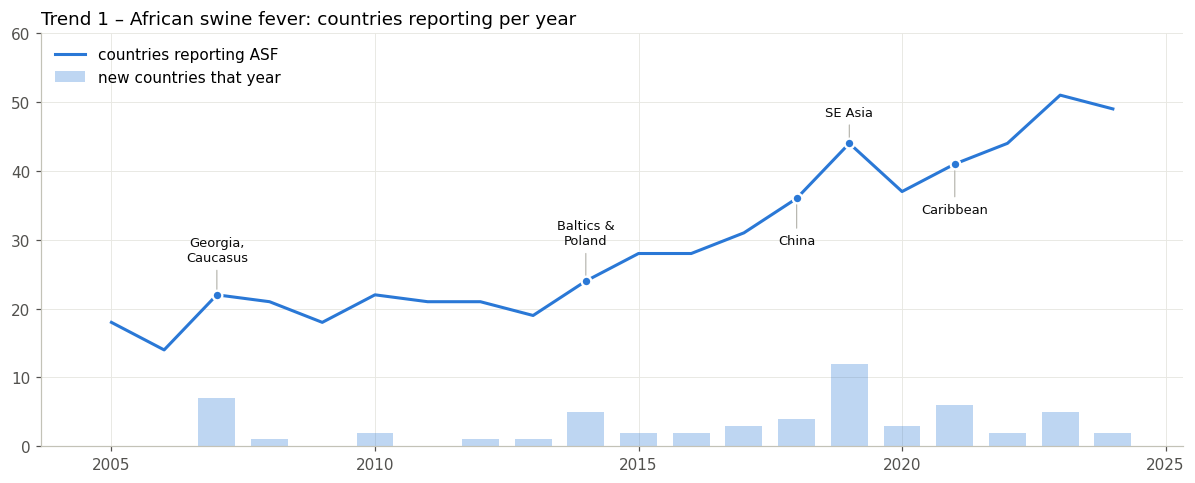

New countries reporting ASF, by year:
Year
2007    Armenia, Burkina Faso, Congo (Rep. of the), Ge...
2008                                           Azerbaijan
2010                         Central African (Rep.), Chad
2012                                              Ukraine
2013                                              Belarus
2014    Cote D'Ivoire, Estonia, Latvia, Lithuania, Poland
2015                                 Cabo verde, Zimbabwe
2016                                        Mali, Moldova
2017                Czech Republic, Romania, Sierra Leone
2018    Belgium, Bulgaria, China (People's Rep. of), H...
2019    Cambodia, Hong Kong, Indonesia, Korea (Rep. of...
2020                               Germany, Greece, India
2021    Bhutan, Dominican (Rep.), Haiti, Malaysia, Nor...
2022                                         Gabon, Nepal
2023    Bangladesh, Bosnia and Herzegovina, Croatia, S...
2024                                  Albania, Montenegro


In [8]:
ASF = "African swine fever virus (Inf. with)"
asf = countries_with[ASF]
asf_new = new_intros[new_intros["Disease"] == ASF].groupby("Year").size().reindex(asf.index, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(asf_new.index, asf_new.values, color=PALETTE[0], alpha=0.3, width=0.7, label="new countries that year")
ax.plot(asf.index, asf.values, color=PALETTE[0], label="countries reporting ASF")
milestones(ax, asf, {
    2007: ("Georgia,\nCaucasus", 22),
    2014: ("Baltics &\nPoland", 24),
    2018: ("China", -30),
    2019: ("SE Asia", 18),
    2021: ("Caribbean", -32),
}, PALETTE[0])
ax.set_ylim(0, 60); ax.set_title("Trend 1 – African swine fever: countries reporting per year")
ax.legend(frameon=False, loc="upper left")
fmt_years(fig); plt.tight_layout(); plt.show()

print("New countries reporting ASF, by year:")
print(new_intros[new_intros["Disease"] == ASF].groupby("Year")["Country"].apply(", ".join).to_string())

## Trend 2: Lumpy skin disease moves out of Africa
LSD reaches the **Middle East and Turkey (2012–14)**, then **Greece and the Balkans (2015–16)**. A regional vaccination campaign cut Balkan outbreaks by 95% in 2017, so the line flattens. It then jumps to **South & East Asia from 2019** (Bangladesh, India, China), including **India's 2022 epidemic** (~155k cattle deaths), and reaches Japan in 2024. Insects spread it locally; cattle trade spreads it long distance.

Sources: [EFSA / Zenodo](https://zenodo.org/records/2583168), [Broglia (vaccine effect)](https://svepm.org.uk/wp-content/uploads/2025/05/Broglia-Lumpy-skin-disease-epidemics-in-Europe-Assessment-of-diease-spread-and-vaccine-effectiveness.pdf), [FAO Asia](https://openknowledge.fao.org/items/ad54fb2c-c1f3-4dbb-af76-daf090261dd6/full), [systematic review](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC10458895/)

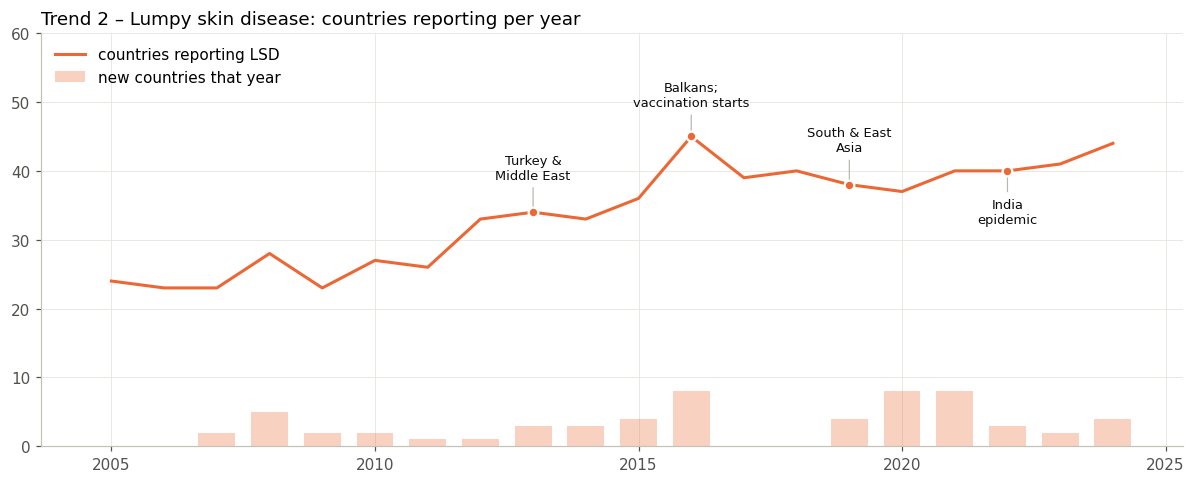

New countries reporting LSD, by year:
Year
2007                                        Kenya, Rwanda
2008       Eritrea, Gambia, Mauritius, Nigeria, Palestine
2009                                      Djibouti, Niger
2010                       Congo (Dem. Rep. of the), Oman
2011                                              Somalia
2012                                              Lebanon
2013                      Iraq, Jordan, Türkiye (Rep. of)
2014                             Azerbaijan, Iran, Kuwait
2015                Armenia, Greece, Russia, Saudi Arabia
2016    Albania, Bulgaria, Georgia, Kazakhstan, Monten...
2019    Bangladesh, China (People's Rep. of), India, S...
2020    Bhutan, Chinese Taipei, Guinea-Bissau, Hong Ko...
2021    Cambodia, Congo (Rep. of the), Laos, Malaysia,...
2022                    Afghanistan, Indonesia, Singapore
2023                               Korea (Rep. of), Libya
2024                        Algeria, Chad, Japan, Tunisia


In [9]:
LSD = "Lumpy skin disease virus (Inf. with)"
lsd = countries_with[LSD]
lsd_new = new_intros[new_intros["Disease"] == LSD].groupby("Year").size().reindex(lsd.index, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(lsd_new.index, lsd_new.values, color=PALETTE[1], alpha=0.3, width=0.7, label="new countries that year")
ax.plot(lsd.index, lsd.values, color=PALETTE[1], label="countries reporting LSD")
milestones(ax, lsd, {
    2013: ("Turkey &\nMiddle East", 22),
    2016: ("Balkans;\nvaccination starts", 20),
    2019: ("South & East\nAsia", 22),
    2022: ("India\nepidemic", -34),
}, PALETTE[1])
ax.set_ylim(0, 60); ax.set_title("Trend 2 – Lumpy skin disease: countries reporting per year")
ax.legend(frameon=False, loc="upper left")
fmt_years(fig); plt.tight_layout(); plt.show()

print("New countries reporting LSD, by year:")
print(new_intros[new_intros["Disease"] == LSD].groupby("Year")["Country"].apply(", ".join).to_string())

## Trend 3: Bird flu changes strain and moves into wild birds
- **Strain shifts:** H5N1 until ~2013 → H5N8/H5N6 (clade 2.3.4.4, from Korea 2014, carried by migratory birds) dominate 2014–2020 → a **new H5N1 (clade 2.3.4.4b)** from late 2020.
- **Wild birds:** countries reporting HPAI in wild/non-poultry birds go from 10 (2019) to 66 (2023). Europe's 2021–22 season was its largest ever, and the virus kept circulating through summer. It reached South America in 2022 and Antarctica in 2024 (skua rows are in this dataset).

Sources: [Korea H5N8 study](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC8001867/), [EFSA 2022](https://www.thepoultrysite.com/news/2022/10/worst-ever-avian-influenza-crisis-in-europe-raises-concerns-efsa), [CDC EID 2025 (Antarctica)](https://wwwnc.cdc.gov/eid/article/31/8/25-0186)

*Left chart counts report rows, so read it as "which strain was common", not as outbreak size. The wild-bird category starts in 2017.*

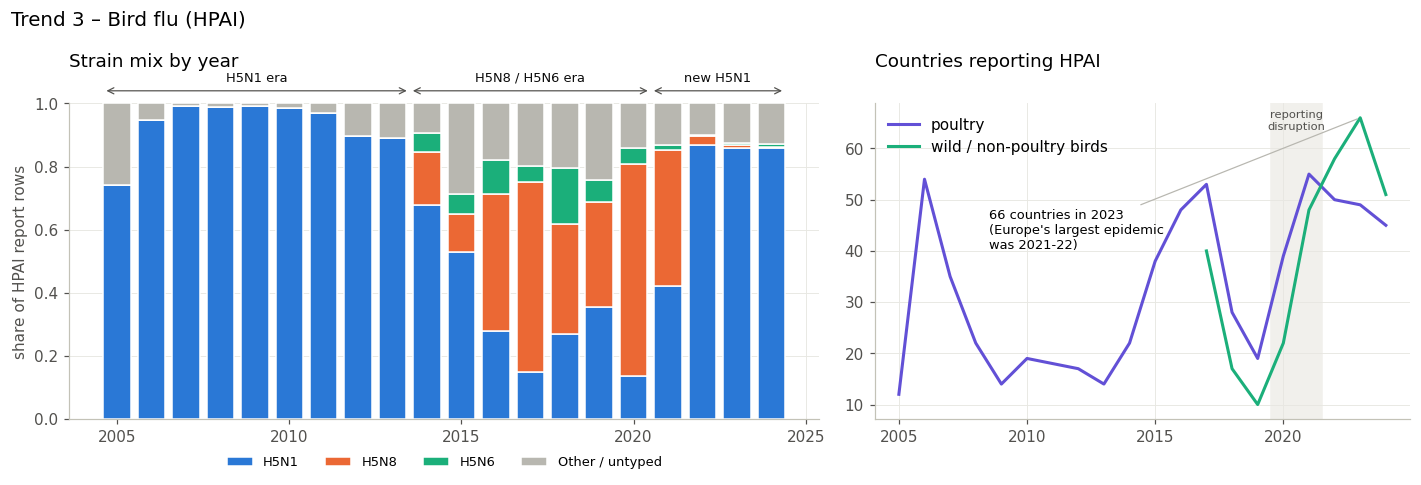

In [10]:
hpai = eda[eda["Disease"].str.startswith("HPAI")]
subtypes = ["H5N1", "H5N8", "H5N6"]
st = pd.crosstab(hpai["Year"], hpai["Serotype/Subtype/Genotype"].where(
    hpai["Serotype/Subtype/Genotype"].isin(subtypes), "Other / untyped"))
st = st[subtypes + ["Other / untyped"]]
st_share = st.div(st.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
bottom = np.zeros(len(st_share))
for col, colr in zip(st_share.columns, PALETTE[:3] + [GREY]):
    ax.bar(st_share.index, st_share[col], bottom=bottom, color=colr, label=col, width=0.8, edgecolor="white", linewidth=1)
    bottom += st_share[col].values
for x0, x1, label in [(2004.6, 2013.5, "H5N1 era"), (2013.5, 2020.5, "H5N8 / H5N6 era"), (2020.5, 2024.4, "new H5N1")]:
    ax.annotate("", (x0, 1.04), (x1, 1.04), xycoords=("data", "axes fraction"), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=0.8))
    ax.text((x0 + x1) / 2, 1.07, label, transform=ax.get_xaxis_transform(), ha="center", fontsize=8.5, color=INK)
ax.set_ylim(0, 1); ax.set_ylabel("share of HPAI report rows")
ax.set_title("Strain mix by year", pad=24)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8.5)

ax = axes[1]
wild = countries_with["HPAI (non-poultry/wild)"].loc[2017:]
poultry = countries_with["HPAI (poultry)"]
ax.plot(poultry.index, poultry.values, color=PALETTE[6], label="poultry")
ax.plot(wild.index, wild.values, color=PALETTE[2], label="wild / non-poultry birds")
shade_2020(ax)
ax.annotate("66 countries in 2023\n(Europe's largest epidemic\nwas 2021-22)", (2023, wild[2023]), xytext=(2008.5, 44), textcoords="data", va="center",
            fontsize=8.5, arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_title("Countries reporting HPAI", pad=24)
ax.legend(frameon=False, loc="upper left")
fig.suptitle("Trend 3 – Bird flu (HPAI)", x=0.01, ha="left", fontsize=13)
fmt_years(fig); plt.tight_layout(); plt.show()

## Trend 4: Clear seasonality
Share of outbreaks reported in Jan–Jun (0.5 = no seasonal pattern).
- **Jul–Dec peak (orange):** insect-borne diseases, because midges, flies and mosquitoes are most active in late summer and autumn. Bluetongue (midges): 93% in Jul–Dec. Lumpy skin disease (biting insects) also peaks in Jul–Dec.
- **Jan–Jun peak (blue):** bird flu in poultry (67%), driven by winter migration of wild birds.
- Bee diseases are excluded (one Iran report makes American foulbrood look 95% Jan–Jun). Screwworm's Jul–Dec share mostly reflects its 2023–24 outbreak growing in the second half of the year, so it isn't a proven seasonal cycle.

Sources: [CDC EID 2024 (bluetongue)](https://wwwnc.cdc.gov/eid/article/30/7/24-0275), [EFSA 2022 (HPAI)](https://www.thepoultrysite.com/news/2022/10/worst-ever-avian-influenza-crisis-in-europe-raises-concerns-efsa)

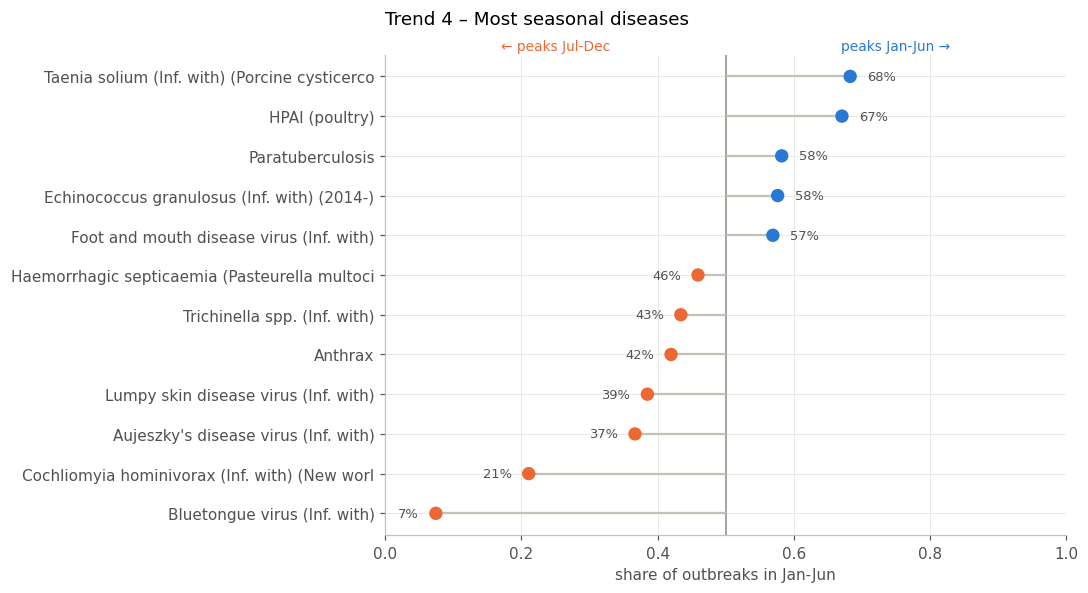

In [11]:
sea = (outbreaks[~outbreaks["Disease"].isin(BEE_DISEASES)]
       .pivot_table(index="Disease", columns="Half", values="New outbreaks", aggfunc="sum").fillna(0))
sea = sea[sea.sum(axis=1) > 20000]
sea["share"] = sea["Jan-Jun"] / sea.sum(axis=1)
sea = sea.sort_values("share")
show = pd.concat([sea.head(7), sea.tail(5)])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvline(0.5, color="#8c8b85", lw=1)
ax.hlines(range(len(show)), 0.5, show["share"], color="#c3c2b7", lw=1.5)
ax.scatter(show["share"], range(len(show)), s=60, zorder=3,
           color=[PALETTE[1] if v < 0.5 else PALETTE[0] for v in show["share"]])
for i, v in enumerate(show["share"]):
    ax.text(v + (0.025 if v >= 0.5 else -0.025), i, f"{v:.0%}", va="center",
            ha="left" if v >= 0.5 else "right", fontsize=8.5, color=MUTED)
ax.set_yticks(range(len(show)), [d[:45] for d in show.index])
ax.set_xlim(0, 1); ax.set_xlabel("share of outbreaks in Jan-Jun")
ax.text(0.25, 1.01, "← peaks Jul-Dec", transform=ax.get_xaxis_transform(), ha="center", fontsize=9, color=PALETTE[1])
ax.text(0.75, 1.01, "peaks Jan-Jun →", transform=ax.get_xaxis_transform(), ha="center", fontsize=9, color=PALETTE[0])
ax.set_title("Trend 4 – Most seasonal diseases", pad=20)
plt.tight_layout(); plt.show()

## Trend 5: Surges are specific epidemics
Each panel is a region's outbreaks per year (bee diseases excluded, own y-scale). The biggest year in each region is labelled with the country and disease behind it.

| Surge | Cause |
|---|---|
| Europe 2008 | Bluetongue serotype 8 in France: 26,500 herds ([CDC EID](https://wwwnc.cdc.gov/eid/article/16/12/10-0412_article)) |
| Asia 2022 | FMD returns to Indonesia, first time since the 1980s ([Global Biosecurity](https://jglobalbiosecurity.com/index.php/up-j-gb/article/view/175)); LSD epidemic in India ([Outlook India](https://www.outlookindia.com/amp/story/national/lumpy-skin-disease-caused-over-1-5-lakh-cattle-deaths-in-2022-rajasthan-accounted-for-nearly-half-news-243704)) |
| Europe 2024 | Bluetongue serotype 3 spreads from the Netherlands into Germany ([CDC EID](https://wwwnc.cdc.gov/eid/article/30/7/24-0275)) |
| Central America 2023–24 | New World screwworm breaks through the Panama barrier and moves north to Mexico ([USDA APHIS](https://www.aphis.usda.gov/livestock-poultry-disease/cattle/ticks/screwworm/outbreak-central-america)) |

⚠️ **Not real surges:**
- **UK bovine TB 2024** (18,855 vs ~5–6k/yr): official GB figures are flat, so this is likely a reporting change ([Defra](https://assets.publishing.service.gov.uk/media/68480e49d0ca5d7801e4e6a8/England_Bovine_Tuberculosis__TB__Quarterly_Overview_Q1_2025.odt)).
- **Americas 2019–21** (Chile echinococcus, 68–105k/yr): most likely a surveillance/reporting change, with no outside source found.

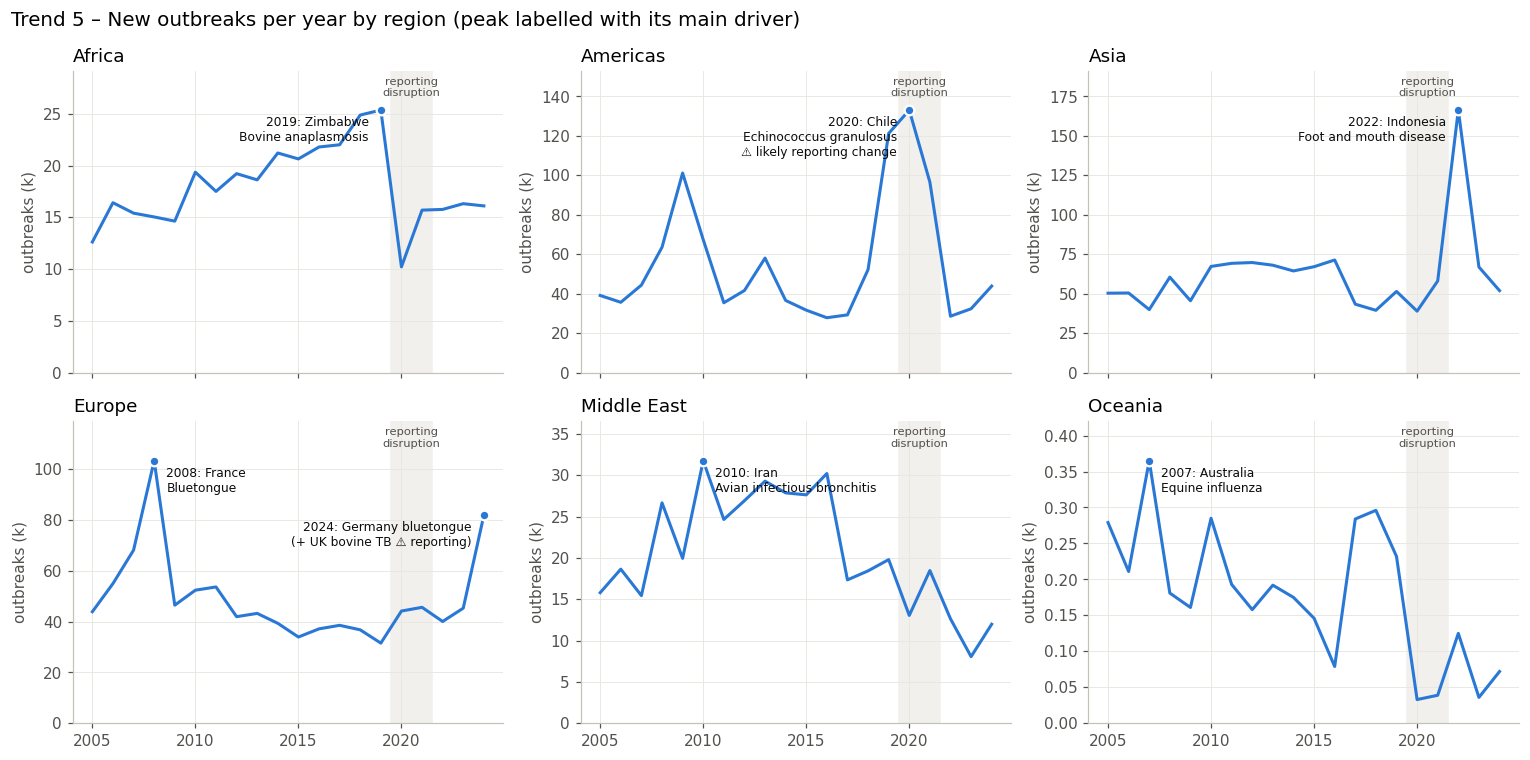

In [12]:
ob_nb = outbreaks[~outbreaks["Disease"].isin(BEE_DISEASES)]
regions = ["Africa", "Americas", "Asia", "Europe", "Middle East", "Oceania"]
by_region = ob_nb.pivot_table(index="Year", columns="World region", values="New outbreaks", aggfunc="sum").fillna(0)

# Top contributor for each region-year, to label peaks
drivers = (ob_nb.groupby(["World region", "Year", "Country", "Disease"])["New outbreaks"].sum()
           .reset_index().sort_values("New outbreaks", ascending=False)
           .drop_duplicates(["World region", "Year"]).set_index(["World region", "Year"]))
# Big totals that come from reporting changes rather than real epidemics (see table above)
REPORTING_ARTIFACTS = {("Chile", "Echinococcus granulosus"), ("United Kingdom", "Bovine tuberculosis")}
EXTRA_NOTES = {"Europe": {2024: "2024: Germany bluetongue\n(+ UK bovine TB ⚠ reporting)"}}

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, r in zip(axes.flat, regions):
    s = by_region[r] / 1000
    shade_2020(ax)
    ax.plot(s.index, s.values, color=PALETTE[0])
    # Label the peak year with its main driver, plus any hand-picked extra events
    peak = s.idxmax()
    d = drivers.loc[(r, peak)]
    flag = "\n⚠ likely reporting change" if (d["Country"], short(d["Disease"])) in REPORTING_ARTIFACTS else ""
    notes = {peak: f"{peak}: {d['Country'].split(' (')[0]}\n{short(d['Disease'])}{flag}"}
    notes.update(EXTRA_NOTES.get(r, {}))
    for yr, text in notes.items():
        ax.scatter([yr], [s[yr]], s=40, color=PALETTE[0], zorder=4, edgecolor="white", linewidth=1.5)
        ax.annotate(text, (yr, s[yr]), xytext=(-8 if yr > 2015 else 8, -4), textcoords="offset points",
                    ha="right" if yr > 2015 else "left", va="top", fontsize=8, color=INK)
    ax.set_title(r); ax.set_ylabel("outbreaks (k)")
    ax.set_ylim(0, s.max() * 1.15)
fig.suptitle("Trend 5 – New outbreaks per year by region (peak labelled with its main driver)", x=0.01, ha="left", fontsize=13)
fmt_years(fig); plt.tight_layout(); plt.show()

## Trend 6: Endemic diseases are flat, then step down in 2020
Long-established diseases (rabies, brucellosis, bovine TB) are roughly flat from 2005 to 2019. In 2020 they drop by about 10–15 countries and stay lower. This matches the lasting fall in countries submitting reports (~173 → ~155, Data check A), so **it most likely reflects reporting, not less disease**. Anthrax is the exception: it was already falling before 2020 (~69 countries in 2012 → ~47 in 2019).

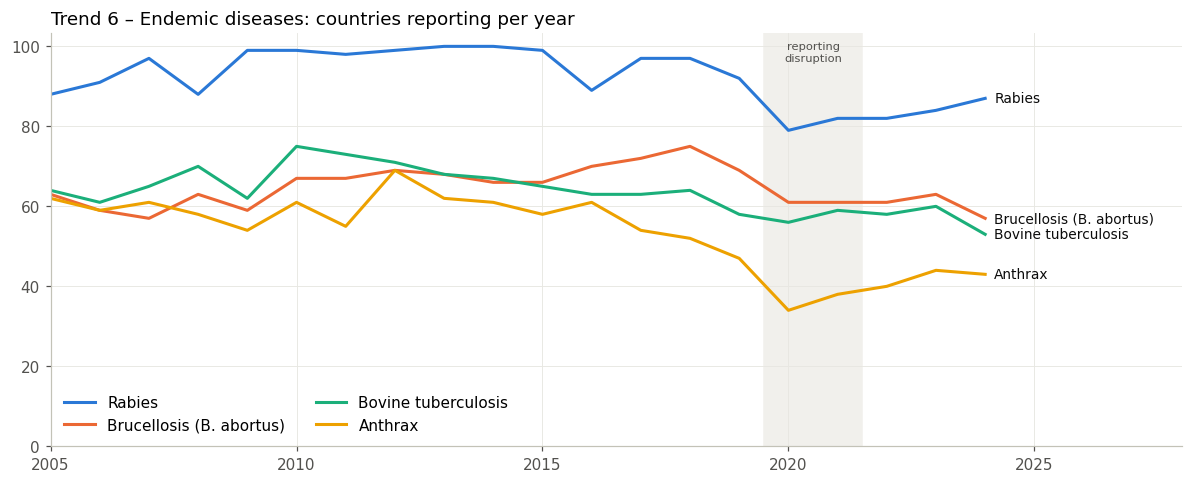

In [13]:
endemic = {
    "Rabies virus (Inf. with)": "Rabies",
    "Brucella abortus (Inf. with)": "Brucellosis (B. abortus)",
    "Bovine tuberculosis": "Bovine tuberculosis",
    "Anthrax": "Anthrax",
}
fig, ax = plt.subplots(figsize=(11, 4.5))
shade_2020(ax)
for i, (dz, label) in enumerate(endemic.items()):
    s = countries_with[dz]
    ax.plot(s.index, s.values, color=PALETTE[i], label=label)
    ax.annotate(label, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_xlim(2005, 2028); ax.set_ylim(0, None)
ax.set_title("Trend 6 – Endemic diseases: countries reporting per year")
ax.legend(frameon=False, loc="lower left", ncol=2)
fmt_years(fig); plt.tight_layout(); plt.show()

## Extra: severity by disease
Case fatality rate (deaths ÷ cases) and culling per case, from species rows in animal units only.

In [14]:
sev = species_rows[species_rows["Measuring units"] == "Animal"].groupby("Disease")[
    ["Cases", "Deaths", "Killed and disposed of"]].sum()
sev = sev[sev["Cases"] > 50000]
sev["CFR"] = sev["Deaths"] / sev["Cases"]
sev["culled_per_case"] = sev["Killed and disposed of"] / sev["Cases"]
sev.sort_values("Cases", ascending=False).head(25).round(2)

,Cases,Deaths,Killed and disposed of,CFR,culled_per_case
Disease,,,,,
Infectious hypodermal and haematopoietic necrosis virus (Inf. with),5.097628e+09,53463021.0,5.096851e+09,0.01,1.00
White spot syndrome virus (Inf. with),2.068131e+09,492113707.0,4.174157e+08,0.24,0.20
Avian infectious bronchitis,1.055063e+09,309695856.0,2.641591e+06,0.29,0.00
Newcastle disease virus (Inf. with),7.861850e+08,241284593.0,3.236481e+07,0.31,0.04
Low pathogenic avian influenza (poultry) (2006-2021),4.791404e+08,159896357.0,2.758579e+07,0.33,0.06
Hepatobacter penaei (Inf. with)(Necrotising hepatopancreatitis)(2011-),1.674722e+08,821000.0,2.800000e+02,0.00,0.00
Perkinsus olseni (Inf. with)(2006-),1.618156e+08,145090270.0,5.800000e+01,0.90,0.00
Infectious bursal disease (Gumboro disease),1.595727e+08,51358702.0,8.561770e+05,0.32,0.01
HPAI (poultry),1.011352e+08,48999083.0,6.425111e+08,0.48,6.35
